## Hough Transform

Number of detected lines: 1462


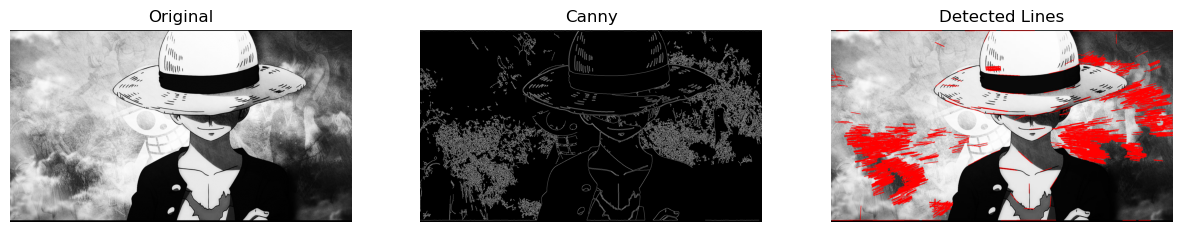

In [14]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('image.jpg', 0)

img1 = cv2.GaussianBlur(img, (3, 3), 0)

canny1 = cv2.Canny(img1, 50, 150)

lines = cv2.HoughLinesP(
    canny1,
    rho=1,
    theta=np.pi / 180,
    threshold=100,
    minLineLength=50,
    maxLineGap=10
)

output = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

lines_list = []

if lines is not None:
    for points in lines:
        x1, y1, x2, y2 = points[0]

        cv2.line(
            output,
            (x1, y1),
            (x2, y2),
            (0, 0, 255),
            2
        )

        lines_list.append([(x1, y1), (x2, y2)])

print("Number of detected lines:", len(lines_list))

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title("Original")
plt.imshow(img, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("Canny")
plt.imshow(canny1, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Detected Lines")
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.show()